# Geometric Transformations: Rotation, Translation and Resizing

A **geometric transformation** changes where pixels are, not what they show. It is used to align camera images, to correct perspective, and to create extra training images for neural networks. This notebook covers the three basic operations on the same road photo used in the other notebooks:
1. **Rotation** around the centre of the image, with and without enlarging the canvas.
2. **Translation**, which moves the image by a fixed offset.
3. **Combining** rotation and translation into a single matrix.
4. **Resizing** with different interpolation methods, and why the method matters.
5. Saving all results to `output/`.

Photo credit: <https://www.flickr.com/photos/smoothgroover22/15104006386>

## 1. Imports

- `cv2` (OpenCV): image I/O, warping and resizing
- `matplotlib`: displaying images
- `numpy`: matrix operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. How a geometric transformation works

Rotation and translation are both **affine transformations**. An affine transformation is described by a 2 × 3 matrix $M$. Every pixel position $(x, y)$ is moved to a new position $(x', y')$:

$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} a & b & t_x \\ c & d & t_y \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

- **Translation** uses $a = d = 1$, $b = c = 0$. Only $t_x$ and $t_y$ are non-zero, and they move the image right and down.
- **Rotation** by an angle $\theta$ with scale $s$ uses $a = s\cos\theta$, $b = s\sin\theta$, $c = -s\sin\theta$, $d = s\cos\theta$. OpenCV's `getRotationMatrix2D` builds this matrix for a chosen centre. A positive angle rotates **counter-clockwise** as seen on screen.

`cv2.warpAffine(image, M, (width, height))` applies the matrix. It does not move pixels forward: for every pixel of the **output** image it looks up the matching position in the input image. This is why there are no holes in the result. When that position falls between two pixels, OpenCV interpolates between them.

**Resizing** is not an affine warp with a different matrix in OpenCV. It is done by `cv2.resize`, which takes a scale factor and an interpolation method. Both are covered in section 7.

## 3. Configuration

- `INPUT_PATH`: the sample image. Photo credit: see the top of the notebook.
- `ROTATION_ANGLE`, `ROTATION_SCALE`: rotation angle in degrees and scale factor for the rotation.
- `TRANSLATION`: the `(tx, ty)` shift in pixels. Positive `tx` moves right, positive `ty` moves down.
- `RESIZE_DOWN`, `RESIZE_UP`: scale factors for shrinking and enlarging.
- `ZOOM`: the `(top, bottom, left, right)` region of the roof-mounted sensor, used for the close-up comparison in section 7.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("Self_Driving_Car.jpg")
OUTPUT_DIR = Path("output")

ROTATION_ANGLE = 20  # degrees, counter-clockwise
ROTATION_SCALE = 1.0
TRANSLATION = (300, 50)  # (tx, ty) in pixels
RESIZE_DOWN = 0.5
RESIZE_UP = 2.0

ZOOM = (120, 200, 500, 600)  # (top, bottom, left, right) of the roof sensor

## 4. Load the image

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Image size (height, width): 661, 1024


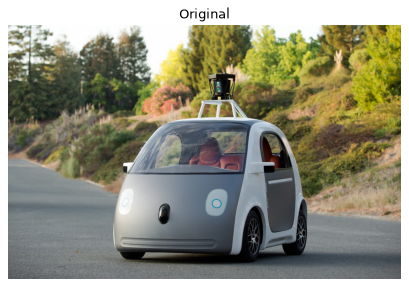

In [4]:
image = load_image(INPUT_PATH)
height, width = image.shape[:2]

print(f"Image size (height, width): {height}, {width}")
show_images({"Original": image})

## 5. Rotation

`cv2.getRotationMatrix2D(centre, angle, scale)` returns the 2 × 3 matrix for a rotation around `centre`. The output here has the **same size** as the input, so the corners of the rotated photo fall outside the canvas and are cut off.

Section 5.1 fixes this: it enlarges the canvas so that the whole rotated image fits.

Rotation matrix:
 [[  0.93969262   0.34202014 -82.16027921]
 [ -0.34202014   0.93969262 195.04590221]]


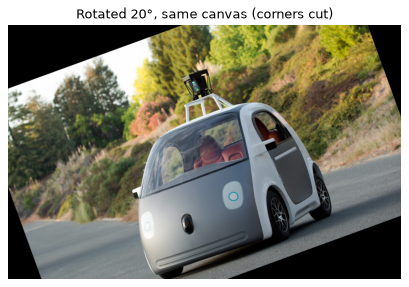

In [5]:
centre = (width / 2, height / 2)
M_rotation = cv2.getRotationMatrix2D(centre, ROTATION_ANGLE, ROTATION_SCALE)
print("Rotation matrix:\n", M_rotation)

rotated_same_size = cv2.warpAffine(image, M_rotation, (width, height))

show_images({f"Rotated {ROTATION_ANGLE}°, same canvas (corners cut)": rotated_same_size})

### 5.1 Rotation with an enlarged canvas

To find the size of the rotated image, take the rectangle of the original image and rotate its four corners. The bounding box of the rotated rectangle is:

$$W' = h\,|\sin\theta| + w\,|\cos\theta|, \qquad H' = h\,|\cos\theta| + w\,|\sin\theta|$$

The matrix also has to be shifted so that the centre of the image lands in the centre of the new canvas. `rotate_expanded` does both.

Same-canvas size: 1024 x 661; expanded size: 1188 x 971


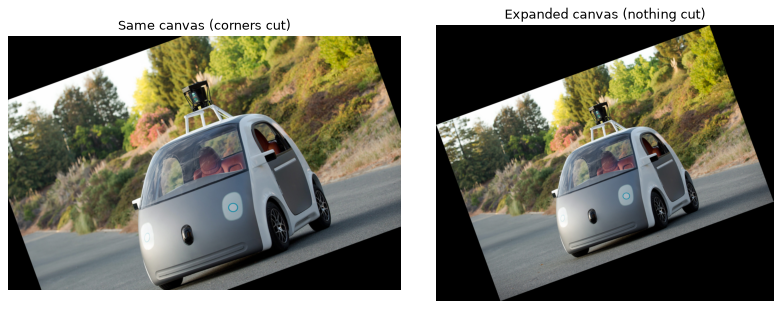

In [6]:
def rotate_expanded(img: np.ndarray, angle: float, scale: float = 1.0) -> np.ndarray:
    """Rotate around the centre and enlarge the canvas so that no corner is cut off."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    cos, sin = np.abs(M[0, 0]), np.abs(M[0, 1])
    new_w = int(h * sin + w * cos)
    new_h = int(h * cos + w * sin)
    # move the centre of the image into the centre of the new canvas
    M[0, 2] += new_w / 2 - w / 2
    M[1, 2] += new_h / 2 - h / 2
    return cv2.warpAffine(img, M, (new_w, new_h))


rotated_expanded = rotate_expanded(image, ROTATION_ANGLE, ROTATION_SCALE)
print(f"Same-canvas size: {width} x {height}; expanded size: {rotated_expanded.shape[1]} x {rotated_expanded.shape[0]}")

show_images({
    "Same canvas (corners cut)": rotated_same_size,
    "Expanded canvas (nothing cut)": rotated_expanded,
})

## 6. Translation

The translation matrix is $\begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \end{bmatrix}$. It shifts every pixel by $(t_x, t_y)$. Pixels that move off the canvas are lost, and the area that is left uncovered is filled with black by default.

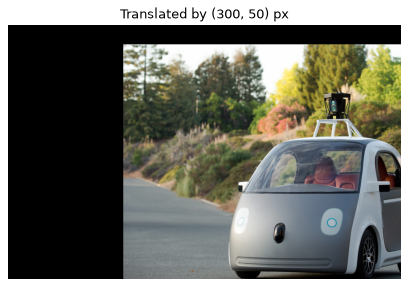

In [7]:
tx, ty = TRANSLATION
M_translation = np.float32([[1, 0, tx],
                            [0, 1, ty]])

translated = cv2.warpAffine(image, M_translation, (width, height))

show_images({f"Translated by ({tx}, {ty}) px": translated})

## 7. Combining rotation and translation

Two warps in a row mean two rounds of interpolation, and each round blurs the image a little. Instead, the two $3 \times 3$ matrices can be multiplied into one, and the image is warped once. The rotation is applied first, then the translation.

$$M = T \cdot R, \qquad T = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \\ 0 & 0 & 1 \end{bmatrix}$$

where $R$ is the rotation matrix written as a $3 \times 3$ matrix, with the bottom row $[0\ 0\ 1]$ added.

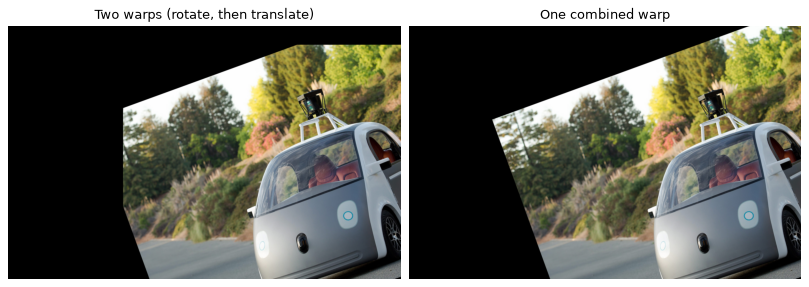

In [8]:
def to_3x3(M: np.ndarray) -> np.ndarray:
    """Append the bottom row [0, 0, 1] to a 2 x 3 affine matrix so that matrices can be multiplied."""
    return np.vstack([M, [0, 0, 1]])


T = to_3x3(M_translation)
R = to_3x3(M_rotation)
M_combined = (T @ R)[:2]  # back to 2 x 3 for warpAffine

combined = cv2.warpAffine(image, M_combined, (width, height))
sequential = cv2.warpAffine(rotated_same_size, M_translation, (width, height))

show_images({
    "Two warps (rotate, then translate)": sequential,
    "One combined warp": combined,
})

## 8. Resizing and interpolation

`cv2.resize` changes the size by a scale factor. When pixels are **created** (enlarging) or **merged** (shrinking), the new pixel values must be estimated. The `interpolation` argument chooses how:

| Method | Good for | Behaviour |
|---|---|---|
| `INTER_NEAREST` | speed, label images | copies the nearest pixel, gives blocky edges |
| `INTER_LINEAR` | general use, enlarging | averages the 4 nearest pixels, fast and smooth |
| `INTER_CUBIC` | enlarging photos | uses 16 pixels, sharper than linear, slower |
| `INTER_AREA` | shrinking | averages all pixels that fall into each new pixel, avoids aliasing |

### 8.1 Shrinking

Shrinking with `INTER_NEAREST` drops most of the pixels, so thin lines such as branches can flicker or disappear (aliasing). `INTER_AREA` averages the pixels first.

Shrunk size: 512 x 330


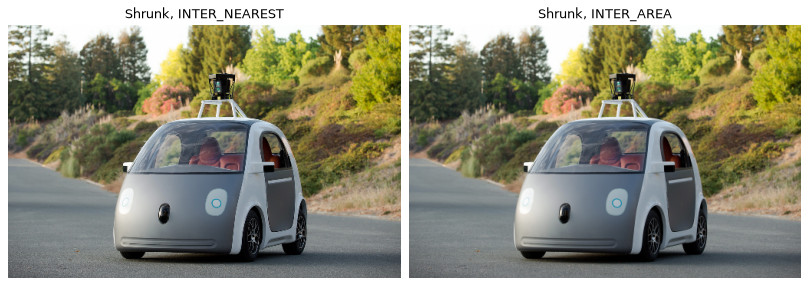

In [9]:
shrunk_nearest = cv2.resize(image, None, fx=RESIZE_DOWN, fy=RESIZE_DOWN, interpolation=cv2.INTER_NEAREST)
shrunk_area = cv2.resize(image, None, fx=RESIZE_DOWN, fy=RESIZE_DOWN, interpolation=cv2.INTER_AREA)

print(f"Shrunk size: {shrunk_area.shape[1]} x {shrunk_area.shape[0]}")
show_images({
    "Shrunk, INTER_NEAREST": shrunk_nearest,
    "Shrunk, INTER_AREA": shrunk_area,
})

### 8.2 Enlarging

Enlarging the whole photo by 4x would make a 4096 × 2644 image, which is slow to display and to save. The comparison is clearer on a small crop around the roof sensor, enlarged 4x with each method.

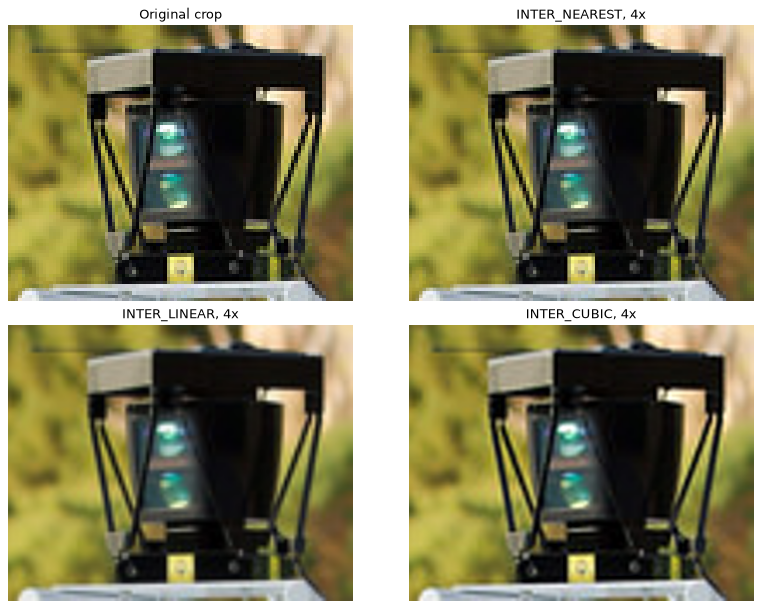

In [10]:
top, bottom, left, right = ZOOM
crop = image[top:bottom, left:right]
zoom_factor = 4

enlarged = {
    name: cv2.resize(crop, None, fx=zoom_factor, fy=zoom_factor, interpolation=method)
    for name, method in {
        "INTER_NEAREST": cv2.INTER_NEAREST,
        "INTER_LINEAR": cv2.INTER_LINEAR,
        "INTER_CUBIC": cv2.INTER_CUBIC,
    }.items()
}

show_images({"Original crop": crop, **{f"{name}, 4x": img for name, img in enlarged.items()}}, cols=2)

### 8.3 Resizing the whole image

`RESIZE_UP` enlarges the full image with `INTER_CUBIC`. `RESIZE_DOWN` shrinks it with `INTER_AREA`, as shown in section 8.1.

In [11]:
enlarged_full = cv2.resize(image, None, fx=RESIZE_UP, fy=RESIZE_UP, interpolation=cv2.INTER_CUBIC)
print(f"Enlarged size: {enlarged_full.shape[1]} x {enlarged_full.shape[0]}")

Enlarged size: 2048 x 1322


## 9. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [12]:
stem = INPUT_PATH.stem
outputs = {
    "rotated_same_canvas": rotated_same_size,
    "rotated_expanded": rotated_expanded,
    "translated": translated,
    "rotate_then_translate_two_warps": sequential,
    "rotate_then_translate_one_warp": combined,
    "shrunk_nearest": shrunk_nearest,
    "shrunk_area": shrunk_area,
    "zoom_crop_nearest": enlarged["INTER_NEAREST"],
    "zoom_crop_cubic": enlarged["INTER_CUBIC"],
    f"enlarged_cubic_{RESIZE_UP:g}x": enlarged_full,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/Self_Driving_Car_rotated_same_canvas.jpg
Saved output/Self_Driving_Car_rotated_expanded.jpg
Saved output/Self_Driving_Car_translated.jpg
Saved output/Self_Driving_Car_rotate_then_translate_two_warps.jpg
Saved output/Self_Driving_Car_rotate_then_translate_one_warp.jpg
Saved output/Self_Driving_Car_shrunk_nearest.jpg
Saved output/Self_Driving_Car_shrunk_area.jpg
Saved output/Self_Driving_Car_zoom_crop_nearest.jpg
Saved output/Self_Driving_Car_zoom_crop_cubic.jpg
Saved output/Self_Driving_Car_enlarged_cubic_2x.jpg


## 10. Conclusion

- A **geometric transformation** moves pixels. An affine transformation is one 2 × 3 matrix, and `cv2.warpAffine` applies it by looking up the source pixel for every output pixel.
- **Rotation** around the centre cuts off the corners unless the canvas is enlarged. The size of the enlarged canvas follows from the bounding box of the rotated rectangle.
- **Translation** shifts the image and leaves an uncovered strip, which is black by default.
- Matrices can be **multiplied**. A rotation and a translation become one matrix and one warp, which keeps more detail than two warps in a row.
- **Resizing** needs an interpolation method. Use `INTER_AREA` to shrink and `INTER_CUBIC` or `INTER_LINEAR` to enlarge. `INTER_NEAREST` is fast but blocky.

These transformations are used throughout the roadmap: a bird's-eye view needs the perspective (projective) version of the same matrix idea, and the flips, rotations and shifts shown here are the standard data augmentation for training traffic sign classifiers.